<a href="https://colab.research.google.com/github/HighlanderJWK/Uczenie-G-bokie/blob/main/Lab03_Keras_klasyfikacja_regresja.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 3 - Trenowanie sieci w Keras: klasyfikacja, regresja i regularyzacja

> **Wersja dla studentów.** Komórki z `# TODO` uzupełnij samodzielnie.

**Kurs:** Uczenie głębokie (Informatyka, II stopień, sem. III, studia niestacjonarne)
**Prowadząca:** dr inż. Natalia Piórkowska
**Środowisko:** Google Colab, GPU T4, TensorFlow / Keras 3

## Cel zajęć

Na poprzednich zajęciach (L1, L2) budowaliśmy sieci "od zera" - liczyliśmy gradienty ręcznie, pisaliśmy własne pętle treningowe. Dziś przechodzimy na poziom, na którym pracuje się na co dzień: **wysokopoziomowe API Keras**. Nauczysz się:

1. budować i trenować sieć MLP do **klasyfikacji wieloklasowej** (Fashion-MNIST) z warstwą softmax i stratą `sparse_categorical_crossentropy`,
2. czytać **krzywe uczenia** i diagnozować niedouczenie / przeuczenie,
3. budować sieć do **regresji** (California Housing), poprawnie standaryzować dane (tylko na zbiorze treningowym!) i porównywać się z **baseline'em**,
4. używać **callbacków**: `EarlyStopping`, `ModelCheckpoint`, `ReduceLROnPlateau`,
5. porównywać **optymalizatory** (SGD, SGD+momentum, RMSprop, Adam) i dobierać **learning rate**,
6. celowo **przeuczyć** sieć, a potem ją "leczyć": Dropout, regularyzacja L2, BatchNormalization,
7. **zapisywać i wczytywać** modele w formacie `.keras`.

## Efekty uczenia (z karty przedmiotu)

- **UGŁ_W01** - zna metody uczenia sieci (funkcje straty, optymalizatory, regularyzacja).
- **UGŁ_W02** - zna zaawansowane narzędzia DL (Keras, callbacki, zapis modeli - element cyklu życia modelu).
- **UGŁ_U01** - formułuje i weryfikuje hipotezy (np. "Dropout zmniejszy różnicę między train a val").
- **UGŁ_U02** - proponuje usprawnienia rozwiązania w oparciu o istniejące biblioteki.

## Powiązanie z wykładem

- **W1** - parametry vs hiperparametry, podział train/val/test, overfitting/underfitting.
- **W2** - warstwa gęsta, aktywacje, softmax, BatchNorm, Dropout.
- **W3** - funkcje straty (MSE, MAE, CCE), optymalizatory (SGD, momentum, RMSProp, Adam), regularyzacja, krzywe uczenia, Keras: `compile` / `fit` / `evaluate`, callbacki. **To główny wykład do tych zajęć.**
- **W4** - metryki klasyfikacji i regresji (zapowiedź - pełna analiza w L5).

## Harmonogram (180 min)

| Czas | Blok |
|---|---|
| 0-10 min | Wstęp, przygotowanie środowiska (sekcja 0) |
| 10-45 min | 1. Klasyfikacja Fashion-MNIST: MLP, softmax, krzywe uczenia (zad. 1.1, 1.2) |
| 45-75 min | 2. Regresja California Housing: standaryzacja, baseline, MSE/MAE (zad. 2.1, 2.2) |
| 75-95 min | 3. Callbacki (zad. 3.1) |
| 95-105 min | **Przerwa (10 min)** |
| 105-130 min | 4. Optymalizatory i learning rate (zad. 4.1, 4.2) |
| 130-160 min | 5. Przeuczenie i regularyzacja: Dropout, L2, BatchNorm (zad. 5.1, 5.2) |
| 160-170 min | 6. Zapis i wczytanie modelu (zad. 6.1) |
| 170-180 min | Pytania kontrolne, podsumowanie, informacje do sprawozdania |

## Wymagania wstępne

- Python, NumPy, matplotlib na poziomie L1-L2.
- Rozumienie: czym jest funkcja straty, gradient, epoka, batch (L1), jak działa MLP i backpropagation (L2).
- Znajomość podziału na zbiór treningowy, walidacyjny i testowy (W1).

## 0. Przygotowanie środowiska

### Włączenie GPU w Colab
W menu wybierz: **Środowisko wykonawcze -> Zmień typ środowiska wykonawczego -> T4 GPU -> Zapisz**. Po zmianie środowisko zostanie zrestartowane, więc zrób to **przed** uruchomieniem pierwszej komórki.

### Tryb szybki
Zmienna `SZYBKI_TRYB` steruje "budżetem obliczeniowym" notebooka. Gdy `SZYBKI_TRYB = True`:
- używamy tylko części danych (np. 2000 pierwszych obrazów),
- trenujemy tylko przez 2-3 epoki.

Wyniki będą wtedy słabsze, ale cały notebook przejdzie w kilka minut nawet na CPU. **Przełącz na `True`, jeśli pracujesz bez GPU** (np. limit GPU w Colab się wyczerpał) albo chcesz najpierw sprawdzić, czy kod działa. Domyślnie wartość jest odczytywana ze zmiennej środowiskowej `DL_FAST` (na zajęciach w Colab będzie to `False`).

In [1]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
import keras
from keras import layers

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, confusion_matrix

# Tryb szybki: True = mniej danych i epok (praca na CPU / szybki test kodu)
SZYBKI_TRYB = os.environ.get("DL_FAST", "0") == "1"
# SZYBKI_TRYB = True   # <- odkomentuj, jeśli pracujesz bez GPU

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("Backend Keras:", keras.backend.backend())
print("SZYBKI_TRYB =", SZYBKI_TRYB)

TensorFlow: 2.21.0 | Keras: 3.13.2
Backend Keras: tensorflow
SZYBKI_TRYB = False


In [2]:
# Sprawdzenie dostępności GPU
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    print("Dostępne GPU:", gpus)
else:
    print("Brak GPU - obliczenia na CPU. Rozważ SZYBKI_TRYB = True.")

# Ziarno losowości: ustawia jednocześnie seed dla Pythona, NumPy i TensorFlow.
# Dzięki temu wyniki są (w przybliżeniu) powtarzalne - na GPU drobne różnice i tak mogą wystąpić.
SEED = 42
keras.utils.set_random_seed(SEED)

Dostępne GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### Funkcja pomocnicza do rysowania krzywych uczenia

Obiekt `History` zwracany przez `model.fit(...)` ma słownik `history.history`, w którym dla każdej metryki zapisana jest lista wartości z kolejnych epok, np. `loss`, `val_loss`, `accuracy`, `val_accuracy`. Napiszmy funkcję, której będziemy używać przez cały notebook.

In [4]:
def rysuj_historie(historia, metryka="accuracy", tytul=""):
    # Rysuje stratę i wybraną metrykę dla zbioru treningowego i walidacyjnego
    h = historia.history if hasattr(historia, "history") else historia
    epoki = np.arange(1, len(h["loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(epoki, h["loss"], "o-", label="train")
    if "val_loss" in h:
        ax[0].plot(epoki, h["val_loss"], "s-", label="walidacja")
    ax[0].set_xlabel("epoka"); ax[0].set_ylabel("strata"); ax[0].set_title(f"{tytul} - strata")
    ax[0].legend(); ax[0].grid(alpha=0.3)
    if metryka in h:
        ax[1].plot(epoki, h[metryka], "o-", label="train")
        if "val_" + metryka in h:
            ax[1].plot(epoki, h["val_" + metryka], "s-", label="walidacja")
        ax[1].set_xlabel("epoka"); ax[1].set_ylabel(metryka); ax[1].set_title(f"{tytul} - {metryka}")
        ax[1].legend(); ax[1].grid(alpha=0.3)
    plt.tight_layout(); plt.show()

## 1. Klasyfikacja wieloklasowa: Fashion-MNIST

### Zbiór danych
Fashion-MNIST to 70 000 obrazów w skali szarości 28x28 przedstawiających 10 kategorii ubrań (60 000 treningowych, 10 000 testowych). Jest trudniejszy niż klasyczny MNIST (cyfry), dlatego lepiej pokazuje różnice między modelami.

### Podział danych - przypomnienie z W1
- **train** - na nim model uczy się parametrów (wag),
- **walidacja (val)** - na nim wybieramy hiperparametry i decydujemy, kiedy przerwać trening,
- **test** - używamy go **raz, na końcu**, do uczciwej oceny. Jeśli patrzymy na test przy dobieraniu hiperparametrów, wynik testowy staje się optymistycznie obciążony.

Keras dostarcza tylko train i test, więc walidację wydzielimy sami z części treningowej.

In [5]:
(x_tr_full, y_tr_full), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

if SZYBKI_TRYB:
    # w trybie szybkim bierzemy tylko początkowe próbki
    x_tr_full, y_tr_full = x_tr_full[:2000], y_tr_full[:2000]
    x_test, y_test = x_test[:500], y_test[:500]

# Normalizacja do [0, 1]: sieci uczą się znacznie stabilniej na małych wartościach niż na 0..255
x_tr_full = x_tr_full.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Wydzielamy walidację: ostatnia 1/6 części treningowej (w pełnym trybie 10 000 obrazów)
n_val = len(x_tr_full) // 6
x_train, y_train = x_tr_full[:-n_val], y_tr_full[:-n_val]
x_val, y_val = x_tr_full[-n_val:], y_tr_full[-n_val:]

NAZWY_KLAS = ["T-shirt/top", "Spodnie", "Sweter", "Sukienka", "Płaszcz",
              "Sandał", "Koszula", "Sneaker", "Torba", "Botek"]

print("train:", x_train.shape, "val:", x_val.shape, "test:", x_test.shape)
print("zakres wartości:", x_train.min(), "-", x_train.max())
print("liczność klas w train:", np.bincount(y_train, minlength=10))

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
train: (50000, 28, 28) val: (10000, 28, 28) test: (10000, 28, 28)
zakres wartości: 0.0 - 1.0
liczność klas w train: [4977 5012 4992 4979 4950 5004 5030 5045 5032 4979]


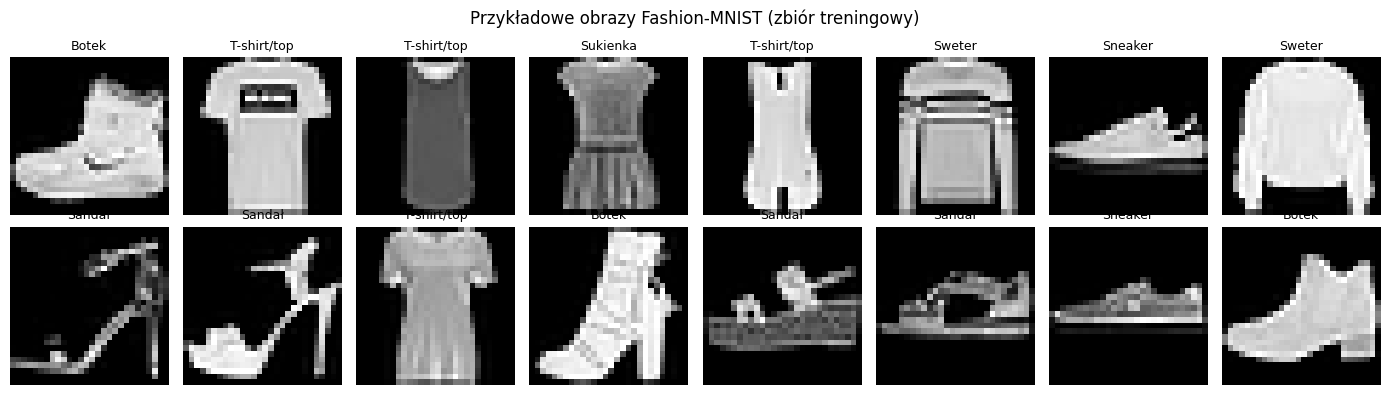

In [6]:
# Podgląd kilku obrazów z etykietami
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i], cmap="gray")
    ax.set_title(NAZWY_KLAS[y_train[i]], fontsize=9)
    ax.axis("off")
plt.suptitle("Przykładowe obrazy Fashion-MNIST (zbiór treningowy)")
plt.tight_layout(); plt.show()

### Softmax i entropia krzyżowa

Ostatnia warstwa klasyfikatora na $K$ klas ma $K$ neuronów zwracających liczby rzeczywiste $z_1, \dots, z_K$ (tzw. **logity**). Funkcja **softmax** zamienia je na rozkład prawdopodobieństwa:

$$p_k = \frac{e^{z_k}}{\sum_{j=1}^{K} e^{z_j}}, \qquad \sum_k p_k = 1.$$

Funkcja straty **kategorialnej entropii krzyżowej** dla jednej próbki z prawdziwą klasą $y$ to

$$L = -\log p_y.$$

Intuicja: jeśli model daje prawdziwej klasie prawdopodobieństwo bliskie 1, strata jest bliska 0; jeśli bliskie 0, strata rośnie do nieskończoności - model jest mocno karany za pewne, ale błędne odpowiedzi.

### `sparse_categorical_crossentropy` vs `categorical_crossentropy`
- `categorical_crossentropy` - etykiety w postaci **one-hot**, np. klasa 3 -> `[0,0,0,1,0,0,0,0,0,0]`,
- `sparse_categorical_crossentropy` - etykiety jako **liczby całkowite** (0..9). Matematycznie to ta sama strata, ale nie trzeba tworzyć macierzy one-hot.

Nasze `y_train` to liczby całkowite, więc użyjemy wersji `sparse_`. **Typowy błąd:** użycie `categorical_crossentropy` z etykietami całkowitymi - Keras zgłosi błąd niezgodności kształtów.

### Ile parametrów ma warstwa gęsta? (W2)
Warstwa `Dense(n_out)` przy wejściu o wymiarze $n_{in}$ ma $n_{in} \cdot n_{out} + n_{out}$ parametrów (wagi + biasy). Dla `Flatten` 28x28 = 784 wejść i 128 neuronów: $784 \cdot 128 + 128 = 100\,480$.

In [7]:
# Model demonstracyjny: najprostszy MLP z jedną warstwą ukrytą
model_demo = keras.Sequential([
    keras.Input(shape=(28, 28)),            # deklaracja kształtu wejścia (bez wymiaru batcha)
    layers.Flatten(),                       # 28x28 -> wektor 784
    layers.Dense(128, activation="relu"),   # warstwa ukryta
    layers.Dense(10, activation="softmax"), # 10 klas -> rozkład prawdopodobieństwa
], name="mlp_demo")

model_demo.summary()   # sprawdź: 100 480 + 1 290 = 101 770 parametrów

Model: "mlp_demo"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

### `compile` i `fit`

- `compile(optimizer, loss, metrics)` - konfiguruje trening: czym optymalizujemy, co minimalizujemy i co dodatkowo raportujemy.
- `fit(x, y, epochs, batch_size, validation_data)` - właściwy trening. W każdej epoce model przechodzi raz przez cały zbiór treningowy w porcjach (mini-batchach) po `batch_size` próbek. Po każdej epoce liczone są metryki na zbiorze walidacyjnym.
- `evaluate(x, y)` - liczy stratę i metryki na podanym zbiorze, bez uczenia.

Epoch 1/10
391/391 - 7s - 19ms/step - accuracy: 0.8046 - loss: 0.5727 - val_accuracy: 0.8319 - val_loss: 0.4698
Epoch 2/10
391/391 - 1s - 3ms/step - accuracy: 0.8529 - loss: 0.4165 - val_accuracy: 0.8586 - val_loss: 0.4058
Epoch 3/10
391/391 - 2s - 4ms/step - accuracy: 0.8669 - loss: 0.3758 - val_accuracy: 0.8696 - val_loss: 0.3774
Epoch 4/10
391/391 - 2s - 4ms/step - accuracy: 0.8754 - loss: 0.3483 - val_accuracy: 0.8751 - val_loss: 0.3619
Epoch 5/10
391/391 - 1s - 3ms/step - accuracy: 0.8820 - loss: 0.3279 - val_accuracy: 0.8799 - val_loss: 0.3522
Epoch 6/10
391/391 - 1s - 3ms/step - accuracy: 0.8882 - loss: 0.3112 - val_accuracy: 0.8816 - val_loss: 0.3467
Epoch 7/10
391/391 - 1s - 3ms/step - accuracy: 0.8918 - loss: 0.2969 - val_accuracy: 0.8802 - val_loss: 0.3436
Epoch 8/10
391/391 - 1s - 3ms/step - accuracy: 0.8969 - loss: 0.2842 - val_accuracy: 0.8827 - val_loss: 0.3411
Epoch 9/10
391/391 - 1s - 3ms/step - accuracy: 0.9010 - loss: 0.2731 - val_accuracy: 0.8802 - val_loss: 0.3461


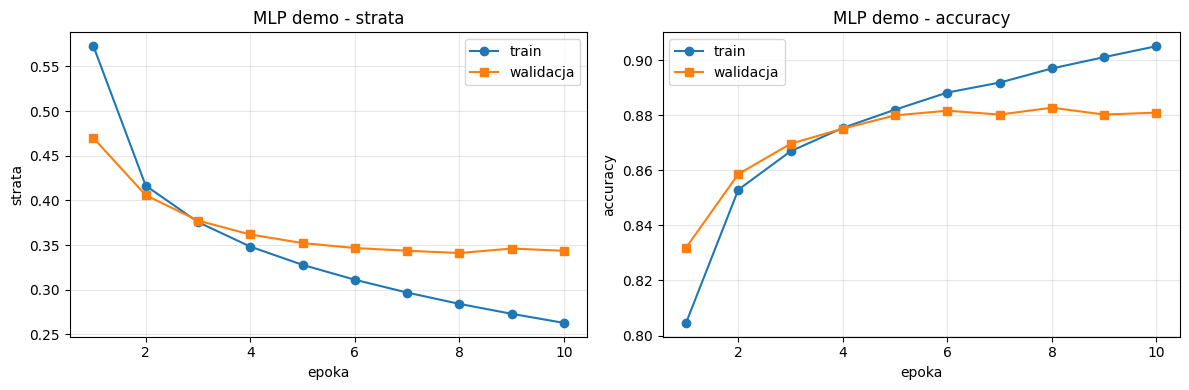

In [8]:
EPOKI_DEMO = 2 if SZYBKI_TRYB else 10

model_demo.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

t0 = time.time()
hist_demo = model_demo.fit(
    x_train, y_train,
    epochs=EPOKI_DEMO,
    batch_size=128,
    validation_data=(x_val, y_val),   # walidacja liczona po każdej epoce
    verbose=2,                        # jedna linia na epokę
)
print(f"czas treningu: {time.time() - t0:.1f} s")
rysuj_historie(hist_demo, tytul="MLP demo")

### Jak czytać krzywe uczenia (W3)?

| Obserwacja | Diagnoza | Co zrobić |
|---|---|---|
| strata train i val wysokie, zbliżone | **niedouczenie** (underfitting) | większy model, dłuższy trening, większy lr |
| strata train maleje, val maleje i stabilizuje się | dobre dopasowanie | ewentualnie zatrzymać w minimum val |
| strata train maleje, val zaczyna **rosnąć** | **przeuczenie** (overfitting) | regularyzacja, więcej danych, early stopping |
| strata skacze / rośnie od początku | za duży learning rate, błąd w danych | zmniejszyć lr, sprawdzić dane |

Uwaga: w pierwszych epokach dokładność walidacyjna bywa **wyższa** niż treningowa. To nie błąd - metryki treningowe są uśredniane w trakcie epoki (model na początku epoki był gorszy), a walidacyjne liczone na końcu epoki.

### Zadanie 1.1 - Głębszy MLP

Zbuduj model `model_mlp` (Sequential) o architekturze:
`Input(28,28) -> Flatten -> Dense(256, relu) -> Dense(128, relu) -> Dense(10, softmax)`.

1. Skompiluj go z optymalizatorem Adam (lr = 1e-3), stratą `sparse_categorical_crossentropy` i metryką `accuracy`.
2. Wytrenuj przez `EPOKI_11` epok z `batch_size=128`, z walidacją na `(x_val, y_val)`. Historię zapisz w `hist_mlp`.
3. Narysuj krzywe uczenia funkcją `rysuj_historie`.
4. Oceń model na zbiorze **testowym** (`evaluate`) i wypisz dokładność.
5. Ręcznie policz liczbę parametrów i porównaj z `model_mlp.count_params()`.

**Kryteria sukcesu (pełny tryb, GPU):** dokładność walidacyjna >= 0.87, testowa >= 0.86; liczba parametrów zgadza się z Twoim rachunkiem.

**Wskazówki:** wzorem jest `model_demo` powyżej. Parametry: $784\cdot256+256$, $256\cdot128+128$, $128\cdot10+10$.

Model: "model_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
391/391 - 9s - 22ms/step - accuracy: 0.8163 - loss: 0.5223 - val_accuracy: 0.8584 - val_loss: 0.4124
Epoch 2/15
391/391 - 1s - 3ms/step - accuracy: 0.8625 - loss: 0.3785 - val_accuracy: 0.8657 - val_loss: 0.3858
Epoch 3/15
391/391 - 1s - 3ms/step - accuracy: 0.8763 - loss: 0.3372 - val_accuracy: 0.8742 - val_loss: 0.3582
Epoch 4/15
391/391 - 1s - 3ms/step - accuracy: 0.8857 - loss: 0.3108 - val_accuracy: 0.8758 - val_loss: 0.3432
Epoch 5/15
391/391 - 1s - 3ms/step - accuracy: 0.8932 - loss: 0.2909 - val_accuracy: 0.8769 - val_loss: 0.3424
Epoch 6/15
391/391 - 1s - 3ms/step - accuracy: 0.8991 - loss: 0.2739 - val_accuracy: 0.8793 - val_loss: 0.3393
Epoch 7/15
391/391 - 1s - 3ms/step - accuracy: 0.9051 - loss: 0.2572 - val_accuracy: 0.8824 - val_loss: 0.3364
Epoch 8/15
391/391 - 2s - 4ms/step - accuracy: 0.9096 - loss: 0.2445 - val_accuracy: 0.8841 - val_loss: 0.3348
Epoch 9/15
391/391 - 1s - 4ms/step - accuracy: 0.9128 - loss: 0.2350 - val_accuracy: 0.8803 - val_loss: 0.3449


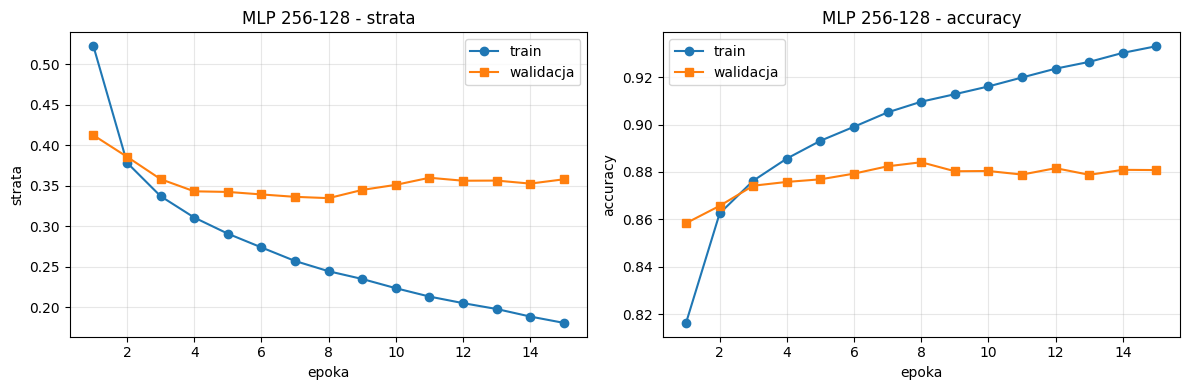

Dokładność testowa: 0.8708
Strata testowa: 0.3846
Parametry warstwa 1: 200960
Parametry warstwa 2: 32896
Parametry wyjściowe: 1290
Razem ręcznie: 235146
model_mlp.count_params(): 235146
Zgodność: True


In [9]:
EPOKI_11 = 2 if SZYBKI_TRYB else 15

# TODO: uzupełnij - zbuduj, skompiluj i wytrenuj model_mlp; zapisz historię w hist_mlp
EPOKI_11 = 2 if SZYBKI_TRYB else 15

model_mlp = keras.Sequential([
    keras.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax"),
], name="model_mlp")

model_mlp.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

model_mlp.summary()

hist_mlp = model_mlp.fit(
    x_train, y_train,
    epochs=EPOKI_11,
    batch_size=128,
    validation_data=(x_val, y_val),
    verbose=2,
)

rysuj_historie(hist_mlp, tytul="MLP 256-128")

# Ocena na zbiorze testowym
test_loss, test_acc = model_mlp.evaluate(x_test, y_test, verbose=0)
print(f"Dokładność testowa: {test_acc:.4f}")
print(f"Strata testowa: {test_loss:.4f}")

# Liczba parametrów:
# 784*256 + 256
# 256*128 + 128
# 128*10 + 10

param_1 = 784 * 256 + 256
param_2 = 256 * 128 + 128
param_3 = 128 * 10 + 10
param_recznie = param_1 + param_2 + param_3

print("Parametry warstwa 1:", param_1)
print("Parametry warstwa 2:", param_2)
print("Parametry wyjściowe:", param_3)
print("Razem ręcznie:", param_recznie)
print("model_mlp.count_params():", model_mlp.count_params())

print("Zgodność:", param_recznie == model_mlp.count_params())

### Gdzie model się myli? Macierz pomyłek

Sama dokładność to za mało - chcemy wiedzieć, **które klasy** są mylone. Macierz pomyłek $C$ ma w komórce $C_{ij}$ liczbę próbek o prawdziwej klasie $i$, które model przypisał do klasy $j$. Na przekątnej są poprawne odpowiedzi. (Pełna analiza metryk klasyfikacji: W4 i L5.)

`model.predict(x)` zwraca macierz prawdopodobieństw o kształcie `(n, 10)`; klasę przewidywaną wybieramy przez `argmax` po osi 1.

suma prawdopodobieństw w 1. wierszu: 1.0


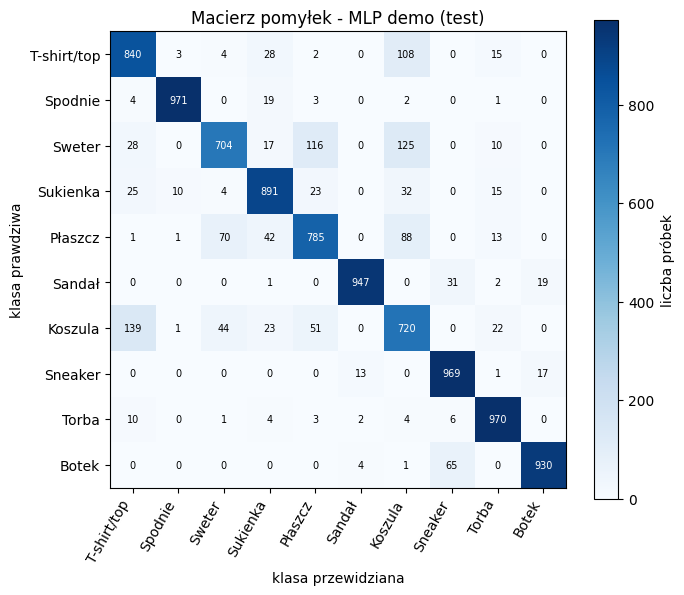

In [10]:
# Demonstracja na model_demo: predykcja i macierz pomyłek
proby = model_demo.predict(x_test, verbose=0)     # (n, 10) prawdopodobieństwa
y_pred_demo = proby.argmax(axis=1)                # klasa o największym prawdopodobieństwie
print("suma prawdopodobieństw w 1. wierszu:", proby[0].sum().round(4))  # softmax -> 1.0

cm = confusion_matrix(y_test, y_pred_demo, labels=range(10))
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(10)); ax.set_xticklabels(NAZWY_KLAS, rotation=60, ha="right")
ax.set_yticks(range(10)); ax.set_yticklabels(NAZWY_KLAS)
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xlabel("klasa przewidziana"); ax.set_ylabel("klasa prawdziwa")
ax.set_title("Macierz pomyłek - MLP demo (test)")
plt.colorbar(im, ax=ax, label="liczba próbek"); plt.tight_layout(); plt.show()

### Zadanie 1.2 - Analiza błędów

Dla modelu `model_mlp` z zadania 1.1:

1. Wyznacz predykcje na zbiorze testowym (`y_pred_mlp`).
2. Policz **dokładność dla każdej klasy osobno** (odsetek poprawnych odpowiedzi wśród próbek danej klasy) i przedstaw ją na wykresie słupkowym z nazwami klas.
3. Znajdź **parę klas najczęściej mylonych** (największy element macierzy pomyłek poza przekątną) i wypisz ją.
4. Pokaż 10 błędnie sklasyfikowanych obrazów z podpisem "prawda / predykcja (prawdopodobieństwo)".

**Kryteria sukcesu:** wykres ma tytuł i opisane osie; potrafisz wyjaśnić, dlaczego właśnie te klasy są mylone.

**Wskazówki:** dokładność klasy $k$ to `cm[k, k] / cm[k].sum()`. Żeby znaleźć maksimum poza przekątną, skopiuj macierz i wyzeruj przekątną (`np.fill_diagonal`), potem `np.unravel_index(m.argmax(), m.shape)`.

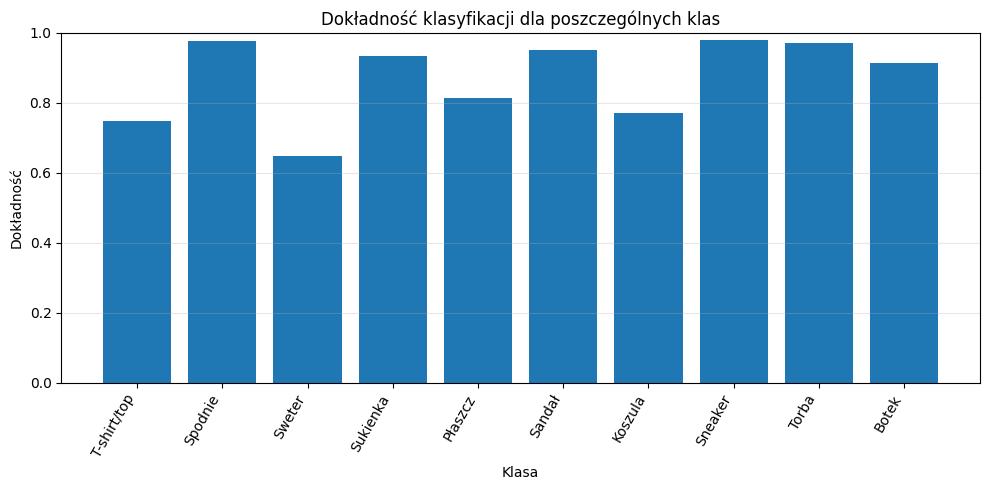

T-shirt/top : 0.748
Spodnie     : 0.977
Sweter      : 0.647
Sukienka    : 0.933
Płaszcz     : 0.815
Sandał      : 0.952
Koszula     : 0.770
Sneaker     : 0.980
Torba       : 0.972
Botek       : 0.914

Najczęstsza pomyłka: T-shirt/top -> Koszula (200 przypadków)


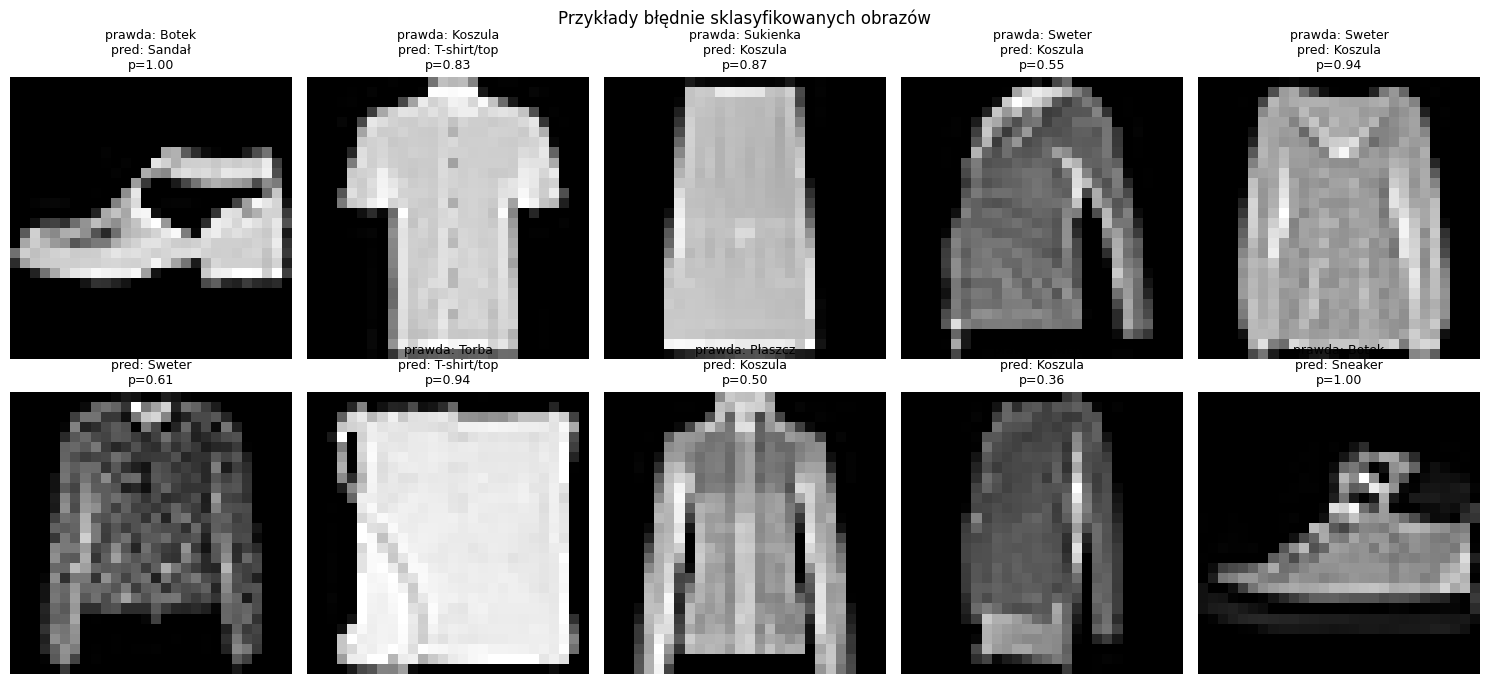

In [12]:
# TODO: uzupełnij - predykcje, dokładność per klasa, najczęściej mylona para, przykłady błędów # Predykcje
proby_mlp = model_mlp.predict(x_test, verbose=0)
y_pred_mlp = proby_mlp.argmax(axis=1)

# Macierz pomyłek
cm_mlp = confusion_matrix(y_test, y_pred_mlp, labels=range(10))

# Dokładność dla każdej klasy
acc_per_class = np.diag(cm_mlp) / cm_mlp.sum(axis=1)

plt.figure(figsize=(10, 5))
plt.bar(NAZWY_KLAS, acc_per_class)
plt.xticks(rotation=60, ha="right")
plt.ylabel("Dokładność")
plt.xlabel("Klasa")
plt.title("Dokładność klasyfikacji dla poszczególnych klas")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

for nazwa, acc in zip(NAZWY_KLAS, acc_per_class):
    print(f"{nazwa:12s}: {acc:.3f}")

# Najczęściej mylona para klas
cm_bez_przekatnej = cm_mlp.copy()
np.fill_diagonal(cm_bez_przekatnej, 0)

i, j = np.unravel_index(
    np.argmax(cm_bez_przekatnej),
    cm_bez_przekatnej.shape
)

print(
    f"\nNajczęstsza pomyłka: {NAZWY_KLAS[i]} -> {NAZWY_KLAS[j]} "
    f"({cm_mlp[i, j]} przypadków)"
)

# Błędnie sklasyfikowane obrazy
bledne_idx = np.where(y_pred_mlp != y_test)[0]

plt.figure(figsize=(15, 7))

for nr, idx in enumerate(bledne_idx[:10]):
    plt.subplot(2, 5, nr + 1)
    plt.imshow(x_test[idx], cmap="gray")

    prawda = y_test[idx]
    pred = y_pred_mlp[idx]
    prawdopodobienstwo = proby_mlp[idx, pred]

    plt.title(
        f"prawda: {NAZWY_KLAS[prawda]}\n"
        f"pred: {NAZWY_KLAS[pred]}\n"
        f"p={prawdopodobienstwo:.2f}",
        fontsize=9
    )
    plt.axis("off")

plt.suptitle("Przykłady błędnie sklasyfikowanych obrazów")
plt.tight_layout()
plt.show()

## 2. Regresja: California Housing

### Zbiór danych
Dane ze spisu powszechnego w Kalifornii (1990): 20 640 dzielnic, 8 cech numerycznych (mediana dochodu, wiek budynków, średnia liczba pokoi, populacja, położenie geograficzne...). Cel: **mediana wartości domu** w dzielnicy, w setkach tysięcy dolarów.

### Co zmienia się względem klasyfikacji?
- warstwa wyjściowa: **1 neuron bez aktywacji** (aktywacja liniowa) - wyjście może być dowolną liczbą rzeczywistą,
- funkcja straty: **MSE** $= \frac{1}{n}\sum_i (y_i - \hat y_i)^2$ lub **MAE** $= \frac{1}{n}\sum_i |y_i - \hat y_i|$ (W3),
- metryki: MAE (w jednostkach celu, łatwa interpretacja), RMSE $= \sqrt{\text{MSE}}$, ewentualnie $R^2$.

MSE silniej karze duże błędy (kwadrat), MAE jest bardziej odporne na wartości odstające. Często trenujemy na MSE (gładki gradient), a raportujemy MAE.

In [14]:
dane = fetch_california_housing(as_frame=True)
df = dane.frame
if SZYBKI_TRYB:
    df = df.iloc[:2000]
print(df.shape)
df.describe().T.round(2)

(20640, 9)


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.87,1.90,0.50,2.56,3.53,4.74,15.00
HouseAge,20640.0,28.64,12.59,1.00,18.00,29.00,37.00,52.00
AveRooms,20640.0,5.43,2.47,0.85,4.44,5.23,6.05,141.91
AveBedrms,20640.0,1.10,0.47,0.33,1.01,1.05,1.10,34.07
Population,20640.0,1425.48,1132.46,3.00,787.00,1166.00,1725.00,35682.00
AveOccup,20640.0,3.07,10.39,0.69,2.43,2.82,3.28,1243.33
Latitude,20640.0,35.63,2.14,32.54,33.93,34.26,37.71,41.95
Longitude,20640.0,-119.57,2.00,-124.35,-121.80,-118.49,-118.01,-114.31
MedHouseVal,20640.0,2.07,1.15,0.15,1.20,1.80,2.65,5.00


### Standaryzacja - tylko na zbiorze treningowym!

Cechy mają bardzo różne skale (populacja - tysiące, mediana dochodu - kilka jednostek). Gradient względem wag przy cechach o dużej skali byłby ogromny, a przy małej - znikomy; trening byłby niestabilny. Dlatego standaryzujemy:

$$x' = \frac{x - \mu_{train}}{\sigma_{train}}.$$

**Kluczowe:** średnią $\mu$ i odchylenie $\sigma$ liczymy **wyłącznie na zbiorze treningowym**, a potem tymi samymi wartościami przekształcamy walidację i test. Gdybyśmy dopasowali `StandardScaler` do całych danych, informacja ze zbioru testowego "przeciekłaby" do treningu (**data leakage**, W4) - wynik testowy byłby zbyt optymistyczny. W praktyce produkcyjnej nowe dane też przekształcamy parametrami z treningu, bo przyszłości nie znamy.

Schemat: `scaler.fit(X_train)` -> `scaler.transform(X_train / X_val / X_test)`.

In [15]:
X = df[dane.feature_names].values.astype("float32")
y = df["MedHouseVal"].values.astype("float32")

# Podział 60 / 20 / 20: najpierw odcinamy test, potem z reszty walidację
X_tmp, X_te_r, y_tmp, y_te_r = train_test_split(X, y, test_size=0.2, random_state=SEED)
X_tr_r, X_va_r, y_tr_r, y_va_r = train_test_split(X_tmp, y_tmp, test_size=0.25, random_state=SEED)

scaler = StandardScaler().fit(X_tr_r)       # fit TYLKO na train
X_tr_s = scaler.transform(X_tr_r)           # transform na wszystkich podzbiorach
X_va_s = scaler.transform(X_va_r)
X_te_s = scaler.transform(X_te_r)

print("train/val/test:", X_tr_s.shape, X_va_s.shape, X_te_s.shape)
print("średnie cech po standaryzacji (train):", X_tr_s.mean(axis=0).round(3))
print("średnie cech po standaryzacji (test): ", X_te_s.mean(axis=0).round(3), "<- nie muszą być 0")

train/val/test: (12384, 8) (4128, 8) (4128, 8)
średnie cech po standaryzacji (train): [ 0.  0. -0.  0. -0.  0.  0.  0.]
średnie cech po standaryzacji (test):  [-0.021  0.014 -0.004  0.011 -0.005 -0.01  -0.026  0.03 ] <- nie muszą być 0


### Baseline - zawsze zaczynaj od punktu odniesienia

Zanim powiesz, że sieć "działa dobrze", porównaj ją z czymś prostym. Najprostszy baseline w regresji: **zawsze przewiduj średnią z treningu**. Jeśli sieć nie jest wyraźnie lepsza, coś jest nie tak (dane, skalowanie, architektura).

In [16]:
# Baseline 0: stała predykcja = średnia celu na zbiorze treningowym
pred_sr = np.full_like(y_te_r, y_tr_r.mean())
mae_sr = mean_absolute_error(y_te_r, pred_sr)
rmse_sr = np.sqrt(mean_squared_error(y_te_r, pred_sr))
print(f"Baseline (średnia): MAE = {mae_sr:.3f}, RMSE = {rmse_sr:.3f}  (jednostka: 100 tys. $)")

Baseline (średnia): MAE = 0.905, RMSE = 1.145  (jednostka: 100 tys. $)


### Zadanie 2.1 - Baseline liniowy

Mocniejszym punktem odniesienia jest **regresja liniowa** (klasyczny model ML, W1).

1. Dopasuj `LinearRegression` ze `sklearn` do `(X_tr_s, y_tr_r)`.
2. Policz MAE i RMSE na zbiorze **testowym**; zapisz w zmiennych `mae_lin`, `rmse_lin`.
3. Wypisz porównanie z baseline'em średniej.

**Kryteria sukcesu (pełny tryb):** MAE regresji liniowej ok. 0.53, wyraźnie mniej niż baseline średniej (ok. 0.9).

In [17]:
# TODO: uzupełnij - dopasuj LinearRegression i policz mae_lin, rmse_lin na teście
model_lin = LinearRegression()
model_lin.fit(X_tr_s, y_tr_r)

y_pred_lin = model_lin.predict(X_te_s)

mae_lin = mean_absolute_error(y_te_r, y_pred_lin)
rmse_lin = np.sqrt(mean_squared_error(y_te_r, y_pred_lin))

print(f"Baseline średnia: MAE = {mae_sr:.3f}, RMSE = {rmse_sr:.3f}")
print(f"Regresja liniowa: MAE = {mae_lin:.3f}, RMSE = {rmse_lin:.3f}")

print(
    f"Poprawa MAE względem średniej: "
    f"{mae_sr - mae_lin:.3f}"
)

Baseline średnia: MAE = 0.905, RMSE = 1.145
Regresja liniowa: MAE = 0.533, RMSE = 0.750
Poprawa MAE względem średniej: 0.372


### Zadanie 2.2 - Sieć do regresji

1. Zbuduj `model_reg`: `Input(8) -> Dense(64, relu) -> Dense(64, relu) -> Dense(1)` (bez aktywacji na wyjściu!).
2. Skompiluj z Adam (lr = 1e-3), stratą `"mse"` i metryką `"mae"`.
3. Wytrenuj `EPOKI_22` epok, `batch_size=64`, z walidacją `(X_va_s, y_va_r)`. Narysuj krzywe (`metryka="mae"`).
4. Policz MAE i RMSE na teście (`mae_nn`, `rmse_nn`) i zestaw w tabeli (pandas DataFrame) z baseline'ami.
5. Narysuj wykres rozrzutu: wartości prawdziwe vs przewidziane na teście, z linią $y = x$.

**Kryteria sukcesu (pełny tryb):** MAE sieci < 0.42 (wyraźnie lepiej niż liniowa).

**Wskazówki:** `model_reg.predict(X_te_s).ravel()` - wyjście ma kształt `(n, 1)`, spłaszczamy je do `(n,)`. Zapomnienie o `ravel()` przy liczeniu `y - y_pred` daje broadcasting do macierzy `(n, n)` - klasyczny, cichy błąd!

Model: "model_reg"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,801 (18.75 KB)

 Trainable params: 4,801 (18.75 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/60
194/194 - 9s - 45ms/step - loss: 1.1040 - mae: 0.6862 - val_loss: 0.6075 - val_mae: 0.5215
Epoch 2/60
194/194 - 5s - 25ms/step - loss: 0.4383 - mae: 0.4691 - val_loss: 0.4147 - val_mae: 0.4476
Epoch 3/60
194/194 - 1s - 3ms/step - loss: 0.3906 - mae: 0.4377 - val_loss: 0.4599 - val_mae: 0.4370
Epoch 4/60
194/194 - 1s - 3ms/step - loss: 0.3744 - mae: 0.4259 - val_loss: 0.4016 - val_mae: 0.4264
Epoch 5/60
194/194 - 1s - 3ms/step - loss: 0.3560 - mae: 0.4161 - val_loss: 0.3881 - val_mae: 0.4191
Epoch 6/60
194/194 - 1s - 4ms/step - loss: 0.3458 - mae: 0.4081 - val_loss: 0.3919 - val_mae: 0.4144
Epoch 7/60
194/194 - 1s - 3ms/step - loss: 0.3417 - mae: 0.4020 - val_loss: 0.4601 - val_mae: 0.4127
Epoch 8/60
194/194 - 1s - 4ms/step - loss: 0.3387 - mae: 0.3964 - val_loss: 0.4243 - val_mae: 0.4074
Epoch 9/60
194/194 - 1s - 4ms/step - loss: 0.3260 - mae: 0.3904 - val_loss: 0.3767 - val_mae: 0.4022
Epoch 10/60
194/194 - 1s - 3ms/step - loss: 0.3158 - mae: 0.3854 - val_loss: 0.3694 - val

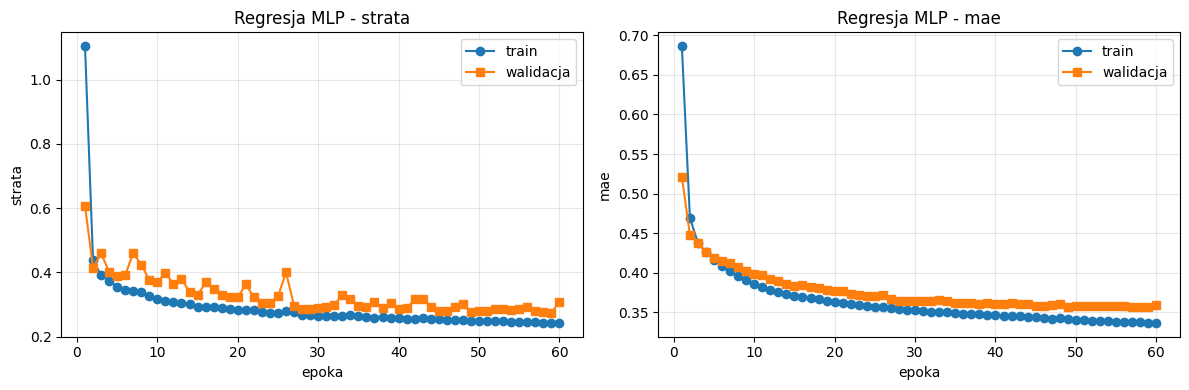

              Model    MAE   RMSE
0           Średnia  0.905  1.145
1  Regresja liniowa  0.533  0.750
2               MLP  0.352  0.522


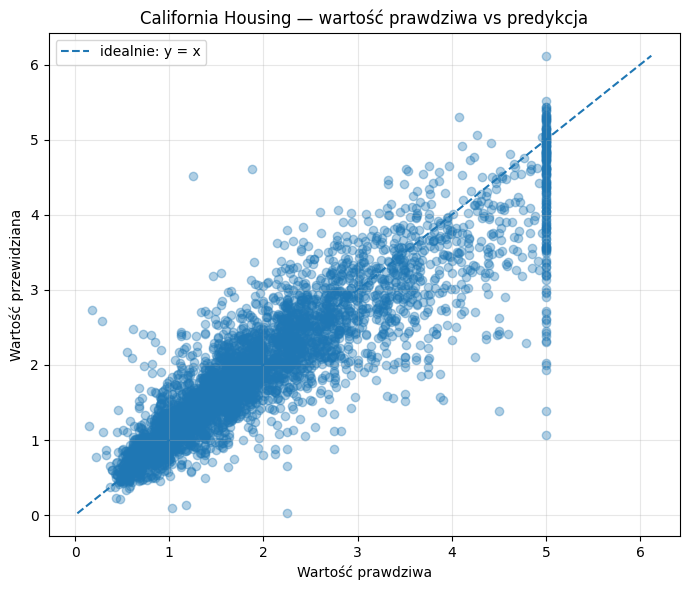

MLP: MAE = 0.352, RMSE = 0.522


In [18]:
EPOKI_22 = 3 if SZYBKI_TRYB else 60

# TODO: uzupełnij - zbuduj model_reg, wytrenuj, porównaj z baseline'ami, narysuj y vs y_pred

model_reg = keras.Sequential([
    keras.Input(shape=(8,)),
    layers.Dense(64, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(1),
], name="model_reg")

model_reg.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="mse",
    metrics=["mae"],
)

model_reg.summary()

hist_reg = model_reg.fit(
    X_tr_s, y_tr_r,
    epochs=EPOKI_22,
    batch_size=64,
    validation_data=(X_va_s, y_va_r),
    verbose=2,
)

rysuj_historie(hist_reg, metryka="mae", tytul="Regresja MLP")

# Predykcje
y_pred_nn = model_reg.predict(X_te_s, verbose=0).ravel()

mae_nn = mean_absolute_error(y_te_r, y_pred_nn)
rmse_nn = np.sqrt(mean_squared_error(y_te_r, y_pred_nn))

# Tabela porównawcza
tabela_reg = pd.DataFrame({
    "Model": [
        "Średnia",
        "Regresja liniowa",
        "MLP"
    ],
    "MAE": [
        mae_sr,
        mae_lin,
        mae_nn
    ],
    "RMSE": [
        rmse_sr,
        rmse_lin,
        rmse_nn
    ]
})

print(tabela_reg.round(3))

# Wykres prawda vs predykcja
plt.figure(figsize=(7, 6))
plt.scatter(y_te_r, y_pred_nn, alpha=0.35)

min_val = min(y_te_r.min(), y_pred_nn.min())
max_val = max(y_te_r.max(), y_pred_nn.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "--",
    label="idealnie: y = x"
)

plt.xlabel("Wartość prawdziwa")
plt.ylabel("Wartość przewidziana")
plt.title("California Housing — wartość prawdziwa vs predykcja")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"MLP: MAE = {mae_nn:.3f}, RMSE = {rmse_nn:.3f}")

## 3. Callbacki - automatyzacja treningu

**Callback** to obiekt, którego metody Keras wywołuje w określonych momentach treningu (początek/koniec epoki, batcha, treningu). Najważniejsze wbudowane:

| Callback | Co robi | Kluczowe argumenty |
|---|---|---|
| `EarlyStopping` | przerywa trening, gdy monitorowana metryka przestaje się poprawiać | `monitor="val_loss"`, `patience`, `restore_best_weights=True` |
| `ModelCheckpoint` | zapisuje model (lub wagi) na dysk, np. tylko gdy jest najlepszy | `filepath` (`.keras` lub `.weights.h5`), `save_best_only=True` |
| `ReduceLROnPlateau` | zmniejsza learning rate, gdy metryka stoi w miejscu | `factor` (np. 0.5), `patience`, `min_lr` |

**Early stopping jako regularyzacja (W3):** zatrzymując trening w minimum `val_loss`, nie pozwalamy sieci "zapamiętać" szumu ze zbioru treningowego. `patience` mówi, ile epok bez poprawy tolerujemy (krzywa walidacyjna jest zaszumiona, więc 1 epoka to za mało). `restore_best_weights=True` przywraca wagi z najlepszej epoki - bez tego zostałyby wagi z ostatniej (gorszej) epoki.

**ReduceLROnPlateau - intuicja:** na początku duży krok pozwala szybko zejść w dół funkcji straty; blisko minimum duży krok "przeskakuje" dolinę, więc krok zmniejszamy.

Epoch 10: early stopping
Restoring model weights from the end of the best epoch: 7.
Wykonano 10 z 50 epok; najlepsza epoka (min val_loss): 7


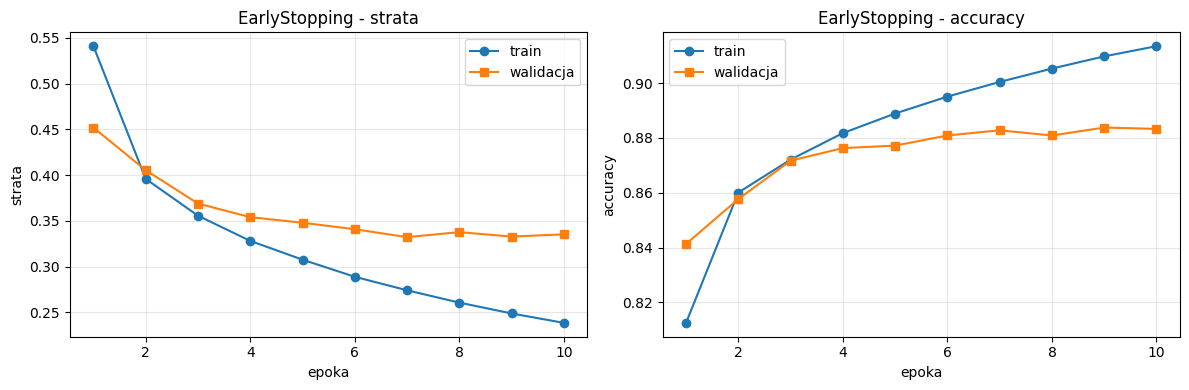

In [19]:
# Demonstracja: EarlyStopping na klasyfikacji Fashion-MNIST z dużą maksymalną liczbą epok
EPOKI_MAX_DEMO = 3 if SZYBKI_TRYB else 50

wczesne_zatrzymanie = keras.callbacks.EarlyStopping(
    monitor="val_loss",          # obserwujemy stratę walidacyjną
    patience=3,                  # 3 epoki bez poprawy -> stop
    restore_best_weights=True,   # przywróć wagi z najlepszej epoki
    verbose=1,
)

model_es = keras.Sequential([keras.Input(shape=(28, 28)), layers.Flatten(),
                             layers.Dense(256, activation="relu"),
                             layers.Dense(10, activation="softmax")])
model_es.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
hist_es = model_es.fit(x_train, y_train, epochs=EPOKI_MAX_DEMO, batch_size=128,
                       validation_data=(x_val, y_val), callbacks=[wczesne_zatrzymanie], verbose=0)

n_epok = len(hist_es.history["loss"])
najlepsza = int(np.argmin(hist_es.history["val_loss"])) + 1
print(f"Wykonano {n_epok} z {EPOKI_MAX_DEMO} epok; najlepsza epoka (min val_loss): {najlepsza}")
rysuj_historie(hist_es, tytul="EarlyStopping")

### Zadanie 3.1 - Trzy callbacki naraz (regresja)

Wytrenuj **nowy** model o architekturze jak w zad. 2.2 (`model_cb`) na danych California Housing, z maksymalną liczbą epok `EPOKI_MAX_31` i trzema callbackami:

- `EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)`,
- `ModelCheckpoint("najlepszy_reg.keras", monitor="val_loss", save_best_only=True)`,
- `ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5)`.

Następnie:
1. wypisz, po ilu epokach trening się zatrzymał i która epoka była najlepsza,
2. narysuj, jak zmieniał się learning rate w kolejnych epokach (Keras zapisuje go w `historia.history["learning_rate"]`),
3. wczytaj model z pliku `najlepszy_reg.keras` i policz jego MAE na teście.

**Kryteria sukcesu:** plik `najlepszy_reg.keras` istnieje; w pełnym trybie trening kończy się przed limitem epok, a lr zmalał co najmniej raz; MAE testowe wczytanego modelu <= MAE z zadania 2.2 (lub bardzo zbliżone).

**Wskazówka:** callbacki przekazujemy jako listę: `fit(..., callbacks=[cb1, cb2, cb3])`.


Epoch 1: val_loss improved from None to 0.55233, saving model to najlepszy_reg.keras

Epoch 1: finished saving model to najlepszy_reg.keras

Epoch 2: val_loss improved from 0.55233 to 0.41773, saving model to najlepszy_reg.keras

Epoch 2: finished saving model to najlepszy_reg.keras

Epoch 3: val_loss improved from 0.41773 to 0.41104, saving model to najlepszy_reg.keras

Epoch 3: finished saving model to najlepszy_reg.keras

Epoch 4: val_loss improved from 0.41104 to 0.38394, saving model to najlepszy_reg.keras

Epoch 4: finished saving model to najlepszy_reg.keras

Epoch 5: val_loss improved from 0.38394 to 0.36872, saving model to najlepszy_reg.keras

Epoch 5: finished saving model to najlepszy_reg.keras

Epoch 6: val_loss did not improve from 0.36872

Epoch 7: val_loss improved from 0.36872 to 0.35744, saving model to najlepszy_reg.keras

Epoch 7: finished saving model to najlepszy_reg.keras

Epoch 8: val_loss did not improve from 0.35744

Epoch 9: val_loss did not improve from 0.3

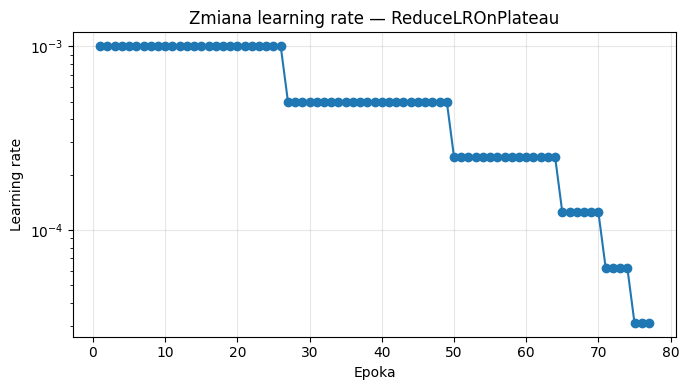

MAE najlepszego modelu: 0.3558
RMSE najlepszego modelu: 0.5295
Plik istnieje: True


In [20]:
EPOKI_MAX_31 = 3 if SZYBKI_TRYB else 200

# TODO: uzupełnij - model_cb z trzema callbackami, wykres lr, wczytanie najlepszego modelu

model_cb = keras.Sequential([
    keras.Input(shape=(8,)),
    layers.Dense(64, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(1),
], name="model_cb")

model_cb.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="mse",
    metrics=["mae"],
)

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1,
)

checkpoint = keras.callbacks.ModelCheckpoint(
    "najlepszy_reg.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1,
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=4,
    min_lr=1e-5,
    verbose=1,
)

# Własne rejestrowanie LR
class RejestrujLR(keras.callbacks.Callback):
    def __init__(self):
        super().__init__()
        self.learning_rates = []

    def on_epoch_end(self, epoch, logs=None):
        lr = float(keras.ops.convert_to_numpy(
            self.model.optimizer.learning_rate
        ))
        self.learning_rates.append(lr)

rejestr_lr = RejestrujLR()

hist_cb = model_cb.fit(
    X_tr_s, y_tr_r,
    epochs=EPOKI_MAX_31,
    batch_size=64,
    validation_data=(X_va_s, y_va_r),
    callbacks=[
        early_stop,
        checkpoint,
        reduce_lr,
        rejestr_lr
    ],
    verbose=0,
)

n_epok_cb = len(hist_cb.history["loss"])
najlepsza_epoka_cb = np.argmin(hist_cb.history["val_loss"]) + 1

print("Liczba wykonanych epok:", n_epok_cb)
print("Najlepsza epoka:", najlepsza_epoka_cb)

# Wykres learning rate
plt.figure(figsize=(7, 4))
plt.plot(
    np.arange(1, len(rejestr_lr.learning_rates) + 1),
    rejestr_lr.learning_rates,
    "o-"
)
plt.xlabel("Epoka")
plt.ylabel("Learning rate")
plt.title("Zmiana learning rate — ReduceLROnPlateau")
plt.yscale("log")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Wczytanie najlepszego modelu
najlepszy_reg = keras.models.load_model("najlepszy_reg.keras")

pred_cb = najlepszy_reg.predict(X_te_s, verbose=0).ravel()
mae_cb = mean_absolute_error(y_te_r, pred_cb)
rmse_cb = np.sqrt(mean_squared_error(y_te_r, pred_cb))

print(f"MAE najlepszego modelu: {mae_cb:.4f}")
print(f"RMSE najlepszego modelu: {rmse_cb:.4f}")
print("Plik istnieje:", os.path.exists("najlepszy_reg.keras"))

---
## Przerwa (10 min)
---

## 4. Optymalizatory i learning rate

Przypomnienie z W3 (wzory dla jednego parametru $w$, gradient $g_t = \nabla_w L$, learning rate $\eta$):

- **SGD:** $w \leftarrow w - \eta\, g_t$. Prosty, ale wolny w "wąskich dolinach" funkcji straty.
- **SGD z momentum:** $v \leftarrow \beta v - \eta g_t,\; w \leftarrow w + v$ (typowo $\beta = 0.9$). Jak kulka toczona po zboczu - "rozpęd" wygładza oscylacje i przyspiesza ruch w spójnym kierunku.
- **RMSprop:** $s \leftarrow \rho s + (1-\rho) g_t^2,\; w \leftarrow w - \frac{\eta}{\sqrt{s}+\epsilon} g_t$. Każdy parametr ma własny, adaptacyjny krok - duże gradienty są tłumione.
- **Adam:** łączy momentum (średnia gradientów $m$) i RMSprop (średnia kwadratów $v$) z korekcją obciążenia: $w \leftarrow w - \eta\,\frac{\hat m}{\sqrt{\hat v}+\epsilon}$. Bardzo dobry wybór domyślny (lr = 1e-3).

**Learning rate** to zwykle najważniejszy hiperparametr. Za mały - trening bardzo wolny; za duży - strata oscyluje lub rośnie (rozbieżność, jak w L1).

Do porównań użyjemy funkcji, która za każdym razem buduje **identyczny** model od nowa (te same seedy), zmieniając tylko optymalizator - wtedy porównanie jest uczciwe.

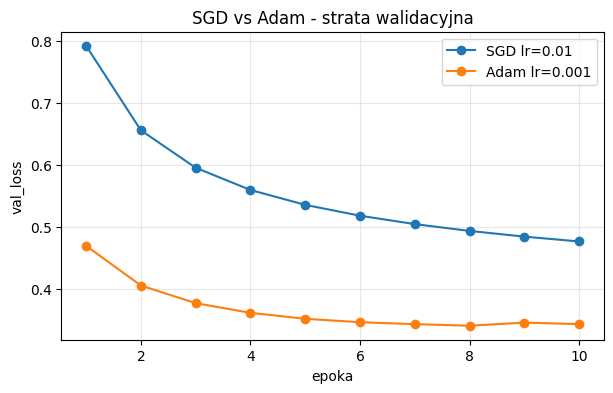

In [21]:
EPOKI_OPT = 2 if SZYBKI_TRYB else 10

def zbuduj_mlp_fashion():
    # Ten sam MLP za każdym razem; seed gwarantuje identyczną inicjalizację wag
    keras.utils.set_random_seed(SEED)
    return keras.Sequential([keras.Input(shape=(28, 28)), layers.Flatten(),
                             layers.Dense(128, activation="relu"),
                             layers.Dense(10, activation="softmax")])

def trenuj_z_optymalizatorem(optymalizator, epoki=EPOKI_OPT):
    # Trenuje świeży model z podanym optymalizatorem i zwraca słownik historii
    model = zbuduj_mlp_fashion()
    model.compile(optimizer=optymalizator, loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    h = model.fit(x_train, y_train, epochs=epoki, batch_size=128,
                  validation_data=(x_val, y_val), verbose=0)
    return h.history

# Demonstracja: zwykły SGD vs Adam
wyniki_demo = {
    "SGD lr=0.01": trenuj_z_optymalizatorem(keras.optimizers.SGD(learning_rate=0.01)),
    "Adam lr=0.001": trenuj_z_optymalizatorem(keras.optimizers.Adam(learning_rate=0.001)),
}
plt.figure(figsize=(7, 4))
for nazwa, h in wyniki_demo.items():
    plt.plot(np.arange(1, len(h["val_loss"]) + 1), h["val_loss"], "o-", label=nazwa)
plt.xlabel("epoka"); plt.ylabel("val_loss"); plt.title("SGD vs Adam - strata walidacyjna")
plt.legend(); plt.grid(alpha=0.3); plt.show()

### Zadanie 4.1 - Porównanie czterech optymalizatorów

Używając `trenuj_z_optymalizatorem`, porównaj:
- `SGD(learning_rate=0.01)`,
- `SGD(learning_rate=0.01, momentum=0.9)`,
- `RMSprop(learning_rate=0.001)`,
- `Adam(learning_rate=0.001)`.

1. Zapisz historie w słowniku `wyniki_opt` (klucz = nazwa).
2. Narysuj na **jednym** wykresie `val_loss` wszystkich wariantów, a na drugim `val_accuracy`.
3. Utwórz tabelę (DataFrame) z najlepszą `val_accuracy` i epoką, w której ją osiągnięto.

**Kryteria sukcesu:** SGD bez momentum powinien być wyraźnie najwolniejszy; potrafisz to wyjaśnić na podstawie wzorów powyżej.

**Uwaga:** optymalizator to obiekt ze stanem (np. bufor momentum) - dla każdego modelu twórz **nową** instancję, nie używaj tej samej dwa razy.

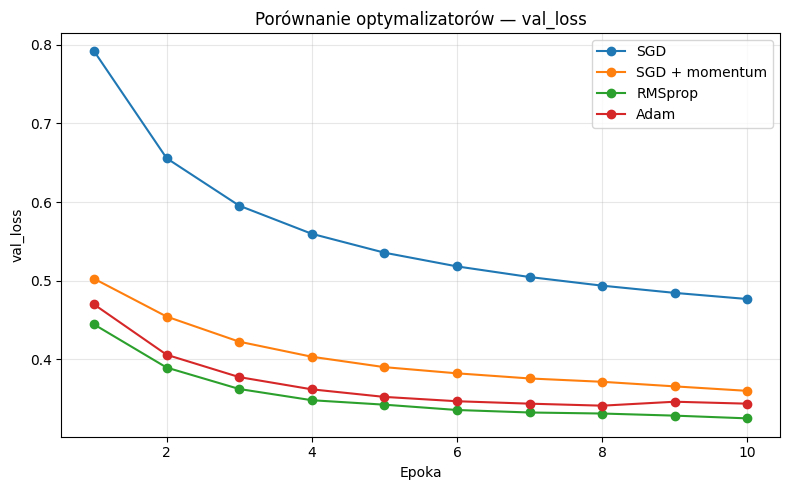

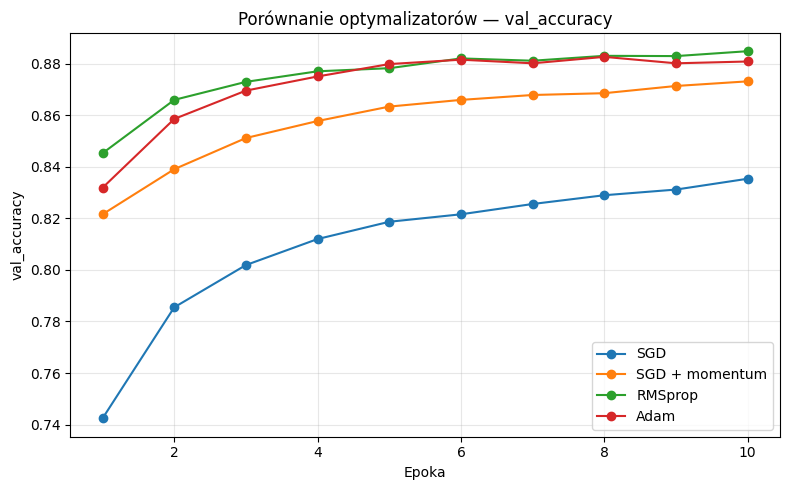

    optymalizator  najlepsza_val_accuracy  epoka
2         RMSprop                  0.8849     10
3            Adam                  0.8827      8
1  SGD + momentum                  0.8732     10
0             SGD                  0.8354     10


In [23]:
# TODO: uzupełnij - porównaj 4 optymalizatory, dwa wykresy i tabela
wyniki_opt = {
    "SGD": trenuj_z_optymalizatorem(
        keras.optimizers.SGD(learning_rate=0.01)
    ),

    "SGD + momentum": trenuj_z_optymalizatorem(
        keras.optimizers.SGD(
            learning_rate=0.01,
            momentum=0.9
        )
    ),

    "RMSprop": trenuj_z_optymalizatorem(
        keras.optimizers.RMSprop(
            learning_rate=0.001
        )
    ),

    "Adam": trenuj_z_optymalizatorem(
        keras.optimizers.Adam(
            learning_rate=0.001
        )
    ),
}

# val_loss
plt.figure(figsize=(8, 5))

for nazwa, h in wyniki_opt.items():
    epoki = np.arange(1, len(h["val_loss"]) + 1)
    plt.plot(epoki, h["val_loss"], "o-", label=nazwa)

plt.xlabel("Epoka")
plt.ylabel("val_loss")
plt.title("Porównanie optymalizatorów — val_loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# val_accuracy
plt.figure(figsize=(8, 5))

for nazwa, h in wyniki_opt.items():
    epoki = np.arange(1, len(h["val_accuracy"]) + 1)
    plt.plot(epoki, h["val_accuracy"], "o-", label=nazwa)

plt.xlabel("Epoka")
plt.ylabel("val_accuracy")
plt.title("Porównanie optymalizatorów — val_accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Tabela
wiersze = []

for nazwa, h in wyniki_opt.items():
    val_acc = np.asarray(h["val_accuracy"])
    idx = np.argmax(val_acc)

    wiersze.append({
        "optymalizator": nazwa,
        "najlepsza_val_accuracy": val_acc[idx],
        "epoka": idx + 1,
    })

tabela_opt = pd.DataFrame(wiersze)
tabela_opt = tabela_opt.sort_values(
    "najlepsza_val_accuracy",
    ascending=False
)

print(tabela_opt.round(4))

### Zadanie 4.2 - Wpływ learning rate

Dla optymalizatora Adam sprawdź learning rate z listy `[1e-4, 1e-3, 1e-2, 1e-1]`.

1. Narysuj krzywe `loss` (treningowej!) dla wszystkich wartości na jednym wykresie.
2. Opisz w komórce markdown (2-3 zdania): który lr jest za mały, który za duży i po czym to widać.

**Kryteria sukcesu:** dla lr = 0.1 widać wyraźnie gorszą (wyższą, niestabilną) stratę, dla 1e-4 - powolny spadek.

**Wskazówka:** jeśli strata dla dużego lr robi się `nan`, to też jest wynik - zapisz to w wnioskach (rozbieżność).

Trening dla lr = 0.0001
Trening dla lr = 0.001
Trening dla lr = 0.01
Trening dla lr = 0.1


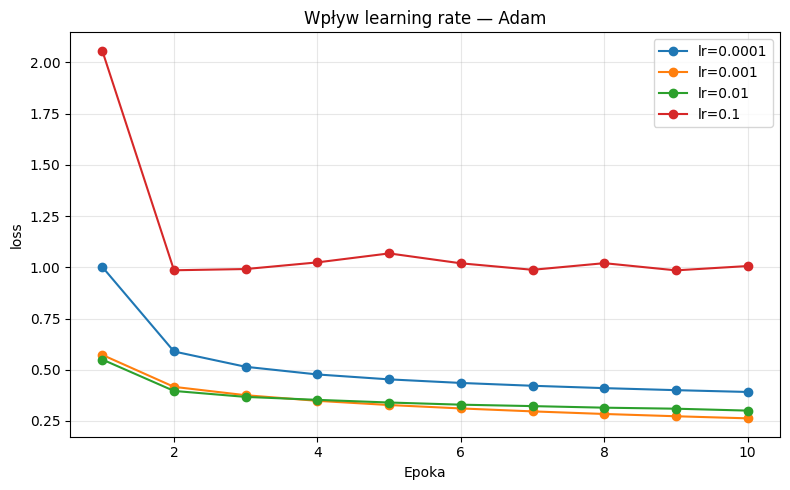

In [24]:
# TODO: uzupełnij - przetestuj 4 wartości lr dla Adama i narysuj stratę treningową
learning_rates = [1e-4, 1e-3, 1e-2, 1e-1]

wyniki_lr = {}

for lr in learning_rates:
    print("Trening dla lr =", lr)

    wyniki_lr[lr] = trenuj_z_optymalizatorem(
        keras.optimizers.Adam(learning_rate=lr)
    )

plt.figure(figsize=(8, 5))

for lr, h in wyniki_lr.items():
    epoki = np.arange(1, len(h["loss"]) + 1)
    plt.plot(
        epoki,
        h["loss"],
        "o-",
        label=f"lr={lr:g}"
    )

plt.xlabel("Epoka")
plt.ylabel("loss")
plt.title("Wpływ learning rate — Adam")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

*Twoje wnioski (zad. 4.2):* ...

## 5. Celowe przeuczenie i jego "leczenie"

### Przeuczenie (overfitting)
Model o dużej pojemności (dużo parametrów) trenowany na małym zbiorze potrafi "zapamiętać" dane treningowe łącznie z szumem. Objaw: strata treningowa spada niemal do zera, a walidacyjna po pewnym czasie **rośnie**. Żeby wyraźnie to zobaczyć, celowo:
- zmniejszymy zbiór treningowy (do 1000 obrazów),
- użyjemy dużej sieci (3 x 512 neuronów, ok. 930 tys. parametrów),
- będziemy trenować długo.

### Metody regularyzacji (W2, W3)
- **Dropout($p$):** w trakcie treningu każdy neuron jest losowo "wyłączany" z prawdopodobieństwem $p$ (pozostałe są skalowane przez $1/(1-p)$). Sieć nie może polegać na pojedynczych neuronach - uczy się reprezentacji redundantnych. Działa jak uśrednianie wielu "podsieci". W predykcji Dropout jest wyłączony.
- **L2 (weight decay):** do straty dodajemy karę $\lambda \sum w^2$. Gradient kary $2\lambda w$ ściąga wagi w stronę zera - preferowane są "gładsze" funkcje. W Keras: `kernel_regularizer=keras.regularizers.l2(lambda)`.
- **BatchNormalization:** normalizuje aktywacje w mini-batchu do średniej 0 i wariancji 1, potem skaluje uczonymi parametrami $\gamma, \beta$:
  $\hat{x} = \frac{x - \mu_B}{\sqrt{\sigma_B^2 + \epsilon}},\; y = \gamma \hat{x} + \beta$.
  Głównie **stabilizuje i przyspiesza** trening (pozwala na większy lr); efekt regularyzujący jest uboczny (szum statystyk batcha) i słabszy niż Dropout.
- **Early stopping** - poznaliśmy w sekcji 3.

parametry: 932362


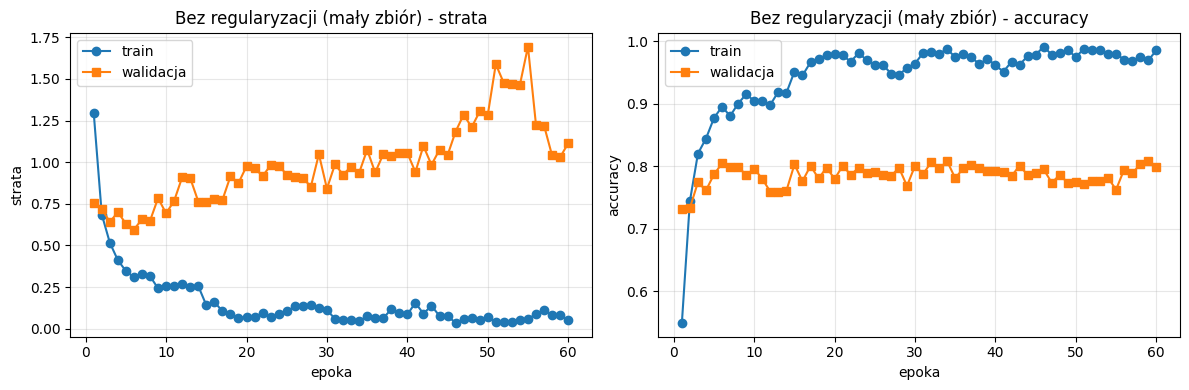

train acc: 0.985, val acc: 0.799, min val_loss w epoce 6


In [25]:
# Mały zbiór treningowy - ułatwia przeuczenie
N_MALY = 500 if SZYBKI_TRYB else 1000
x_maly, y_maly = x_train[:N_MALY], y_train[:N_MALY]
EPOKI_REG = 3 if SZYBKI_TRYB else 60

def zbuduj_przeuczony():
    # Duży MLP bez regularyzacji: 784 -> 512 -> 512 -> 512 -> 10
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([keras.Input(shape=(28, 28)), layers.Flatten()])
    for _ in range(3):
        model.add(layers.Dense(512, activation="relu"))
    model.add(layers.Dense(10, activation="softmax"))
    return model

def trenuj_reg(model, epoki=EPOKI_REG):
    # Wspólna procedura treningu dla wszystkich wariantów regularyzacji
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model.fit(x_maly, y_maly, epochs=epoki, batch_size=64,
                     validation_data=(x_val, y_val), verbose=0).history

model_over = zbuduj_przeuczony()
print("parametry:", model_over.count_params())
h_over = trenuj_reg(model_over)
rysuj_historie(h_over, tytul="Bez regularyzacji (mały zbiór)")
print(f"train acc: {h_over['accuracy'][-1]:.3f}, val acc: {h_over['val_accuracy'][-1]:.3f}, "
      f"min val_loss w epoce {int(np.argmin(h_over['val_loss'])) + 1}")

### Zadanie 5.1 - Dropout i L2

Napisz funkcję `zbuduj_regularyzowany(dropout=0.0, l2=0.0, batchnorm=False)`, która buduje taką samą architekturę jak `zbuduj_przeuczony`, ale:
- jeśli `l2 > 0`, każda warstwa ukryta `Dense` ma `kernel_regularizer=keras.regularizers.l2(l2)`,
- jeśli `batchnorm=True`, po każdej warstwie `Dense(512)` (bez aktywacji) dodaj `BatchNormalization()`, a następnie `Activation("relu")`,
- jeśli `dropout > 0`, po każdej warstwie ukrytej (po aktywacji) dodaj `Dropout(dropout)`.

Następnie wytrenuj funkcją `trenuj_reg` dwa warianty i zapisz historie:
- `h_drop` - Dropout 0.5,
- `h_l2` - L2 z $\lambda = 10^{-3}$.

**Kryteria sukcesu (pełny tryb):** dla obu wariantów rosnąca część `val_loss` jest wyraźnie mniejsza niż bez regularyzacji, a różnica między train i val accuracy maleje.

**Wskazówki:** pamiętaj o `keras.utils.set_random_seed(SEED)` na początku funkcji (uczciwe porównanie). Kolejność `Dense -> BatchNorm -> ReLU -> Dropout` to popularny wybór; w literaturze spotyka się też BN po aktywacji.

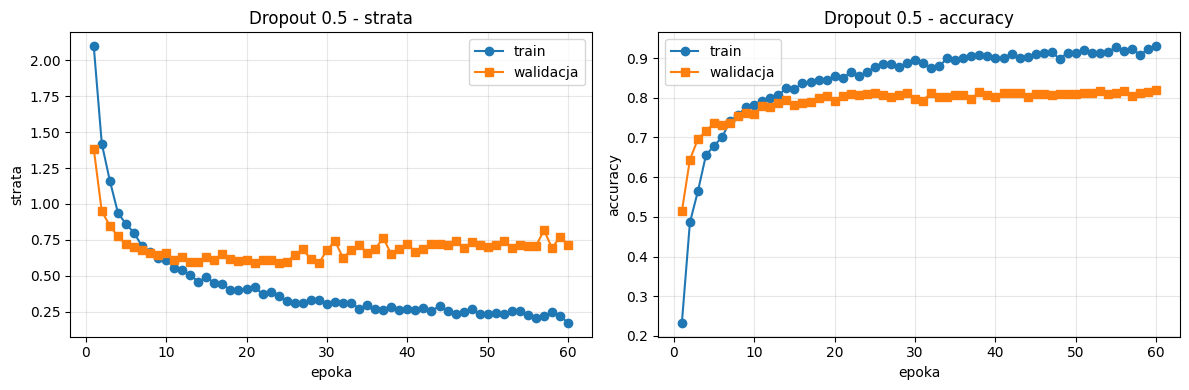

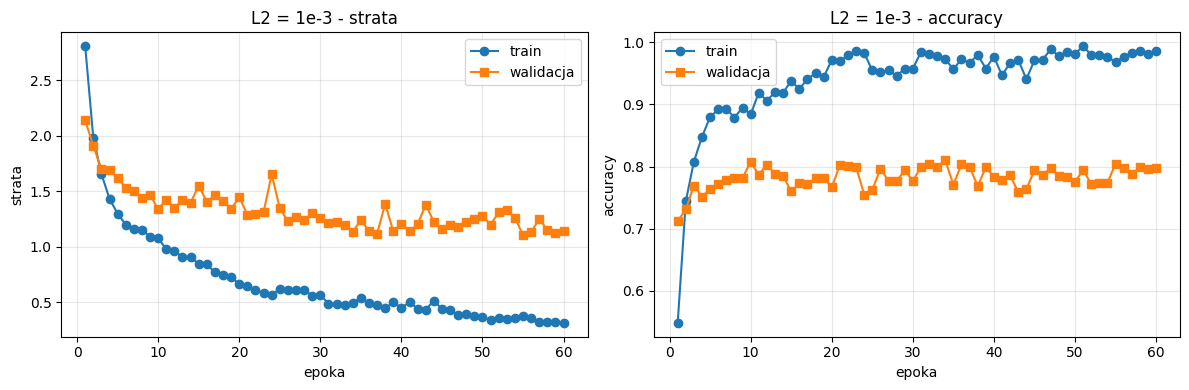

In [26]:
# TODO: uzupełnij - funkcja zbuduj_regularyzowany oraz historie h_drop i h_l2
def zbuduj_regularyzowany(dropout=0.0, l2=0.0, batchnorm=False):
    keras.utils.set_random_seed(SEED)

    model = keras.Sequential()
    model.add(keras.Input(shape=(28, 28)))
    model.add(layers.Flatten())

    regulator = (
        keras.regularizers.l2(l2)
        if l2 > 0
        else None
    )

    for _ in range(3):

        if batchnorm:
            # Bez aktywacji w Dense,
            # ponieważ ReLU dodamy po BatchNorm
            model.add(
                layers.Dense(
                    512,
                    kernel_regularizer=regulator
                )
            )

            model.add(layers.BatchNormalization())
            model.add(layers.Activation("relu"))

        else:
            model.add(
                layers.Dense(
                    512,
                    activation="relu",
                    kernel_regularizer=regulator
                )
            )

        if dropout > 0:
            model.add(layers.Dropout(dropout))

    model.add(
        layers.Dense(
            10,
            activation="softmax"
        )
    )

    return model


# Dropout
model_drop = zbuduj_regularyzowany(
    dropout=0.5
)

h_drop = trenuj_reg(model_drop)

# L2
model_l2 = zbuduj_regularyzowany(
    l2=1e-3
)

h_l2 = trenuj_reg(model_l2)

rysuj_historie(
    h_drop,
    tytul="Dropout 0.5"
)

rysuj_historie(
    h_l2,
    tytul="L2 = 1e-3"
)

### Zadanie 5.2 - BatchNormalization i zestawienie

1. Wytrenuj wariant z BatchNorm (`h_bn`) oraz wariant łączony BatchNorm + Dropout 0.3 (`h_bn_drop`).
2. Na jednym wykresie narysuj `val_loss` wszystkich pięciu wariantów (bez regularyzacji, Dropout, L2, BN, BN+Dropout).
3. Zbuduj tabelę: najlepsza `val_accuracy`, `val_accuracy` w ostatniej epoce, różnica `accuracy - val_accuracy` w ostatniej epoce (miara przeuczenia).
4. Sformułuj w markdown **hipotezę** przed uruchomieniem (np. "BN poprawi szybkość, ale słabiej ograniczy przeuczenie niż Dropout") i zweryfikuj ją po wynikach (UGŁ_U01).

**Kryteria sukcesu:** tabela i wykres kompletne, hipoteza zweryfikowana wynikami.

*Hipoteza (przed uruchomieniem):* ...

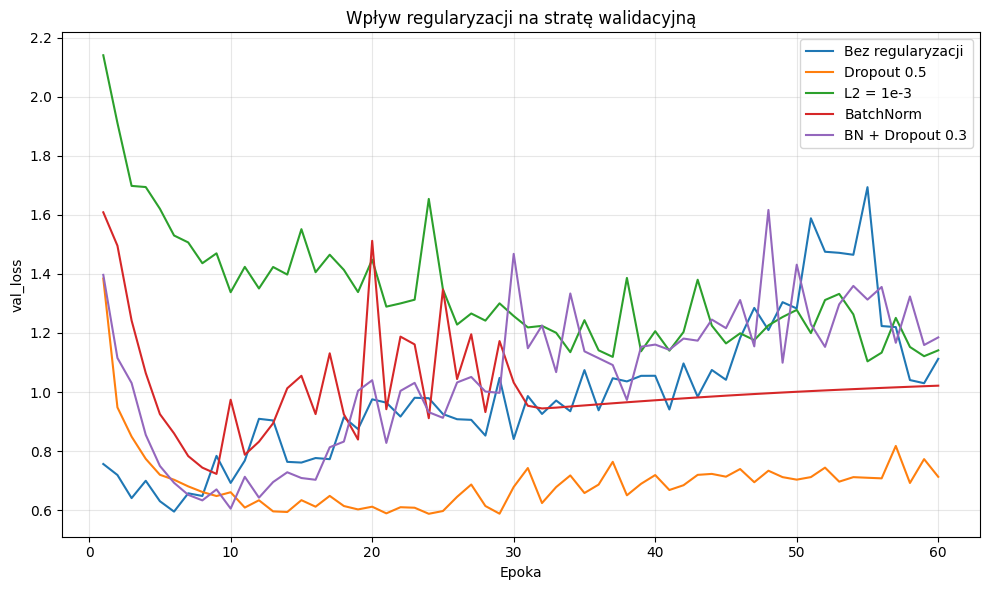

             wariant  najlepsza val_accuracy  ostatnia val_accuracy  \
1        Dropout 0.5                  0.8197                 0.8197   
3          BatchNorm                  0.8144                 0.8132   
4   BN + Dropout 0.3                  0.8126                 0.8014   
2          L2 = 1e-3                  0.8100                 0.7981   
0  Bez regularyzacji                  0.8088                 0.7987   

   ostatnia train_accuracy  train-val gap  min val_loss epoka  
1                    0.930         0.1103                  24  
3                    1.000         0.1868                   9  
4                    0.988         0.1866                  10  
2                    0.987         0.1889                  55  
0                    0.985         0.1863                   6  


In [28]:
# TODO: uzupełnij - warianty BN i BN+Dropout, wspólny wykres i tabela porównawcza
# BatchNorm
model_bn = zbuduj_regularyzowany(
    batchnorm=True
)

h_bn = trenuj_reg(model_bn)

# BatchNorm + Dropout
model_bn_drop = zbuduj_regularyzowany(
    batchnorm=True,
    dropout=0.3
)

h_bn_drop = trenuj_reg(model_bn_drop)

# Wszystkie historie
historie_reg = {
    "Bez regularyzacji": h_over,
    "Dropout 0.5": h_drop,
    "L2 = 1e-3": h_l2,
    "BatchNorm": h_bn,
    "BN + Dropout 0.3": h_bn_drop,
}

# Wspólny wykres val_loss
plt.figure(figsize=(10, 6))

for nazwa, h in historie_reg.items():
    epoki = np.arange(1, len(h["val_loss"]) + 1)
    plt.plot(
        epoki,
        h["val_loss"],
        label=nazwa
    )

plt.xlabel("Epoka")
plt.ylabel("val_loss")
plt.title("Wpływ regularyzacji na stratę walidacyjną")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Tabela
wiersze = []

for nazwa, h in historie_reg.items():

    best_val_acc = np.max(h["val_accuracy"])
    last_val_acc = h["val_accuracy"][-1]
    last_train_acc = h["accuracy"][-1]

    gap = last_train_acc - last_val_acc

    wiersze.append({
        "wariant": nazwa,
        "najlepsza val_accuracy": best_val_acc,
        "ostatnia val_accuracy": last_val_acc,
        "ostatnia train_accuracy": last_train_acc,
        "train-val gap": gap,
        "min val_loss epoka": np.argmin(h["val_loss"]) + 1,
    })

tabela_regularyzacja = pd.DataFrame(wiersze)

tabela_regularyzacja = tabela_regularyzacja.sort_values(
    "najlepsza val_accuracy",
    ascending=False
)

print(tabela_regularyzacja.round(4))

*Weryfikacja hipotezy:* ...

## 6. Zapis i wczytanie modelu

Wytrenowany model to element cyklu życia systemu (W1, W2): trzeba go zapisać, wersjonować, wczytać w innym procesie (np. serwis predykcyjny). W Keras 3:

| Co | Jak | Zawiera |
|---|---|---|
| pełny model | `model.save("plik.keras")`, `keras.models.load_model("plik.keras")` | architekturę, wagi, konfigurację `compile` i stan optymalizatora |
| tylko wagi | `model.save_weights("plik.weights.h5")`, `model.load_weights(...)` | tylko wartości wag - architekturę trzeba odtworzyć w kodzie |

Format `.keras` to archiwum zip (konfiguracja JSON + wagi). Starszy format `.h5` dla pełnych modeli oraz `SavedModel` są w Keras 3 przestarzałe. **Pamiętaj:** w Colab pliki zapisane na dysku maszyny wirtualnej znikają po zakończeniu sesji - aby je zachować, pobierz je lub zapisz na Google Drive.

Zapis wraz ze stanem optymalizatora pozwala **wznowić trening** dokładnie tam, gdzie go przerwano.

In [29]:
# Demonstracja: zapis i wczytanie pełnego modelu
model_demo.save("model_demo.keras")
wczytany = keras.models.load_model("model_demo.keras")

p1 = model_demo.predict(x_test[:100], verbose=0)
p2 = wczytany.predict(x_test[:100], verbose=0)
print("Predykcje identyczne:", np.allclose(p1, p2, atol=1e-6))
print("Rozmiar pliku: %.1f kB" % (os.path.getsize("model_demo.keras") / 1024))
print("Optymalizator wczytanego modelu:", type(wczytany.optimizer).__name__)

Predykcje identyczne: True
Rozmiar pliku: 1215.3 kB
Optymalizator wczytanego modelu: Adam


### Zadanie 6.1 - Zapis wag i wznowienie treningu

1. Zbuduj funkcją `zbuduj_regularyzowany(dropout=0.5)` model, wytrenuj go 2 epoki na `x_maly` (funkcja `trenuj_reg(model, epoki=2)`) i zapisz **same wagi** do `wagi_dropout.weights.h5`.
2. Zbuduj **nowy** model tą samą funkcją, wczytaj do niego wagi i sprawdź (`np.allclose`), że predykcje na `x_test[:100]` są identyczne. Pamiętaj, że Dropout w `predict` jest wyłączony - dlatego wynik jest deterministyczny.
3. Zapisz pierwszy model w całości do `model_dropout.keras`, wczytaj go i **kontynuuj trening** jeszcze 2 epoki przez `fit` (bez ponownego `compile`!). Wypisz `val_accuracy` przed i po.

**Kryteria sukcesu:** oba sprawdzenia `np.allclose` dają `True`; wczytany model trenuje się dalej bez błędu.

**Wskazówka:** nowy model z kroku 2 nie musi być skompilowany, żeby wczytać wagi i wykonać `predict`.

In [30]:
# TODO: uzupełnij - zapis/wczytanie wag, zapis pełnego modelu i wznowienie treningu
# 1. Model z Dropoutem i trening przez 2 epoki
model_d1 = zbuduj_regularyzowany(
    dropout=0.5
)

h_d1 = trenuj_reg(
    model_d1,
    epoki=2
)

# Predykcje przed zapisem
pred_przed = model_d1.predict(
    x_test[:100],
    verbose=0
)

# Zapis samych wag
model_d1.save_weights(
    "wagi_dropout.weights.h5"
)

print(
    "Plik wag istnieje:",
    os.path.exists("wagi_dropout.weights.h5")
)

# 2. Nowy model i wczytanie wag
model_d2 = zbuduj_regularyzowany(
    dropout=0.5
)

model_d2.load_weights(
    "wagi_dropout.weights.h5"
)

pred_po = model_d2.predict(
    x_test[:100],
    verbose=0
)

print(
    "Predykcje po wczytaniu wag identyczne:",
    np.allclose(
        pred_przed,
        pred_po,
        atol=1e-6
    )
)

# 3. Zapis całego modelu
model_d1.save(
    "model_dropout.keras"
)

# Predykcje oryginalnego modelu
pred_pelny_1 = model_d1.predict(
    x_test[:100],
    verbose=0
)

# Wczytanie całego modelu
model_d_loaded = keras.models.load_model(
    "model_dropout.keras"
)

pred_pelny_2 = model_d_loaded.predict(
    x_test[:100],
    verbose=0
)

print(
    "Pełny model daje identyczne predykcje:",
    np.allclose(
        pred_pelny_1,
        pred_pelny_2,
        atol=1e-6
    )
)

# val_accuracy przed kontynuacją
val_acc_przed = h_d1["val_accuracy"][-1]

# Kontynuacja treningu BEZ compile()
h_continue = model_d_loaded.fit(
    x_maly,
    y_maly,
    epochs=2,
    batch_size=64,
    validation_data=(x_val, y_val),
    verbose=2,
)

val_acc_po = h_continue.history["val_accuracy"][-1]

print(
    f"val_accuracy przed: {val_acc_przed:.4f}"
)

print(
    f"val_accuracy po:    {val_acc_po:.4f}"
)

Plik wag istnieje: True


Predykcje po wczytaniu wag identyczne: True
Pełny model daje identyczne predykcje: True
Epoch 1/2
16/16 - 6s - 394ms/step - accuracy: 0.5830 - loss: 1.1200 - val_accuracy: 0.6938 - val_loss: 0.8583
Epoch 2/2
16/16 - 0s - 31ms/step - accuracy: 0.6510 - loss: 0.9734 - val_accuracy: 0.7042 - val_loss: 0.7735
val_accuracy przed: 0.6442
val_accuracy po:    0.7042


## Pytania kontrolne

1. Dlaczego w ostatniej warstwie klasyfikatora na 10 klas używamy softmax, a w regresji warstwy liniowej? Co by się stało, gdyby w regresji cen domów użyć sigmoidy?
2. Czym różni się `sparse_categorical_crossentropy` od `categorical_crossentropy`? Kiedy używamy której?
3. Dlaczego `StandardScaler` dopasowujemy tylko do zbioru treningowego? Jak nazywa się błąd polegający na dopasowaniu go do całych danych i jakie ma skutki?
4. Ile parametrów ma warstwa `Dense(64)` po wejściu o wymiarze 8? A `BatchNormalization` po niej (ile z nich jest uczonych gradientowo)?
5. Co robi `restore_best_weights=True` w `EarlyStopping` i dlaczego jest ważne?
6. Wyjaśnij, czym Adam różni się od zwykłego SGD. Dlaczego SGD bez momentum uczy się wolniej?
7. Na wykresie strata walidacyjna rośnie od 8. epoki, a treningowa dalej spada. Jak to nazywamy i jakie trzy działania podejmiesz?
8. Jak działa Dropout w trakcie treningu, a jak w predykcji? Dlaczego przeskalowuje się aktywacje przez $1/(1-p)$?

## Podsumowanie - co warto zapamiętać

- Keras: `Sequential` / `Input` -> `compile(optimizer, loss, metrics)` -> `fit(..., validation_data=...)` -> `evaluate` / `predict`.
- **Klasyfikacja:** wyjście `Dense(K, softmax)` + `sparse_categorical_crossentropy` (etykiety całkowite). **Regresja:** wyjście `Dense(1)` liniowe + MSE (raportuj MAE/RMSE).
- **Normalizuj dane;** parametry skalowania dopasowuj **tylko na train** - inaczej wyciek danych.
- Zawsze porównuj z **baseline'em** (średnia, regresja liniowa) - bez tego nie wiesz, czy sieć cokolwiek daje.
- **Krzywe uczenia** to podstawowe narzędzie diagnostyczne: niedouczenie vs przeuczenie.
- **Callbacki:** `EarlyStopping(restore_best_weights=True)`, `ModelCheckpoint(save_best_only=True)`, `ReduceLROnPlateau`.
- **Learning rate** jest najważniejszym hiperparametrem; Adam (1e-3) to dobry punkt startowy, SGD+momentum - solidna alternatywa.
- **Regularyzacja:** Dropout i L2 zmniejszają lukę train-val; BatchNorm głównie stabilizuje trening; najlepsze lekarstwo to więcej danych.
- Zapis: `.keras` (pełny model, wznowienie treningu) lub `.weights.h5` (same wagi).

## Do sprawozdania końcowego

Z tego laboratorium umieść w sprawozdaniu (zwięźle, maks. 1,5 strony):

1. **Krzywe uczenia** MLP z zad. 1.1 z krótką diagnozą (w której epoce zaczyna się przeuczenie) oraz dokładność testową.
2. **Tabelę regresji** z zad. 2.2 (średnia / regresja liniowa / MLP; MAE i RMSE) i wykres y vs y_pred z komentarzem o obciętych wartościach.
3. **Porównanie optymalizatorów** (zad. 4.1) - wykres i 2-3 zdania interpretacji.
4. **Tabelę regularyzacji** z zad. 5.2 wraz z **hipotezą i jej weryfikacją** (UGŁ_U01).
5. Jedną **propozycję usprawnienia** (UGŁ_U02), np. inny harmonogram lr, AdamW, augmentacja, inna architektura - z uzasadnieniem.

## Zadanie dodatkowe (dla chętnych) - własny callback i harmonogram lr

1. Napisz własny callback `ZatrzymajPrzyDokladnosci(keras.callbacks.Callback)`, który:
   - w `on_epoch_end` zapisuje do listy bieżący learning rate optymalizatora (`float(self.model.optimizer.learning_rate)`),
   - przerywa trening (`self.model.stop_training = True`), gdy `val_accuracy` przekroczy zadany próg (argument konstruktora), i wypisuje komunikat.
2. Wytrenuj MLP 256-128 na Fashion-MNIST z optymalizatorem Adam, którego learning rate jest harmonogramem `keras.optimizers.schedules.CosineDecay(initial_learning_rate=1e-3, decay_steps=...)` (liczba kroków = epoki x liczba batchy na epokę), z progiem 0.89.
3. Narysuj zapisany przez callback przebieg learning rate.

**Wskazówka:** liczba batchy na epokę to `ceil(len(x_train) / batch_size)`.

Epoch 1/20
391/391 - 5s - 12ms/step - accuracy: 0.8157 - loss: 0.5248 - val_accuracy: 0.8551 - val_loss: 0.4148
Epoch 2/20
391/391 - 1s - 3ms/step - accuracy: 0.8642 - loss: 0.3754 - val_accuracy: 0.8651 - val_loss: 0.3828
Epoch 3/20
391/391 - 1s - 3ms/step - accuracy: 0.8783 - loss: 0.3350 - val_accuracy: 0.8702 - val_loss: 0.3692
Epoch 4/20
391/391 - 1s - 3ms/step - accuracy: 0.8873 - loss: 0.3077 - val_accuracy: 0.8761 - val_loss: 0.3534
Epoch 5/20
391/391 - 1s - 3ms/step - accuracy: 0.8944 - loss: 0.2858 - val_accuracy: 0.8775 - val_loss: 0.3409
Epoch 6/20
391/391 - 1s - 4ms/step - accuracy: 0.9017 - loss: 0.2668 - val_accuracy: 0.8787 - val_loss: 0.3345
Epoch 7/20
391/391 - 2s - 5ms/step - accuracy: 0.9079 - loss: 0.2496 - val_accuracy: 0.8797 - val_loss: 0.3355
Epoch 8/20
391/391 - 1s - 3ms/step - accuracy: 0.9135 - loss: 0.2347 - val_accuracy: 0.8790 - val_loss: 0.3363
Epoch 9/20
391/391 - 1s - 3ms/step - accuracy: 0.9189 - loss: 0.2196 - val_accuracy: 0.8835 - val_loss: 0.3230


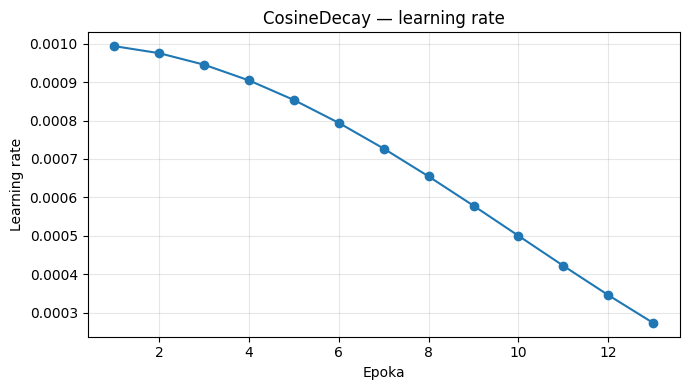

In [31]:
EPOKI_DOD = 2 if SZYBKI_TRYB else 20

# TODO: uzupełnij - własny callback + CosineDecay

class ZatrzymajPrzyDokladnosci(keras.callbacks.Callback):

    def __init__(self, prog):
        super().__init__()
        self.prog = prog
        self.learning_rates = []

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}

        # W przypadku harmonogramu learning rate
        lr = self.model.optimizer.learning_rate

        if callable(lr):
            lr = lr(
                self.model.optimizer.iterations
            )

        lr = float(
            keras.ops.convert_to_numpy(lr)
        )

        self.learning_rates.append(lr)

        val_acc = logs.get(
            "val_accuracy"
        )

        if (
            val_acc is not None
            and val_acc >= self.prog
        ):
            print(
                f"\nOsiągnięto val_accuracy = "
                f"{val_acc:.4f} >= {self.prog:.4f}. "
                "Zatrzymuję trening."
            )

            self.model.stop_training = True


BATCH_SIZE_DOD = 128

liczba_batchy = int(
    np.ceil(
        len(x_train)
        / BATCH_SIZE_DOD
    )
)

liczba_krokow = (
    EPOKI_DOD
    * liczba_batchy
)

schedule = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=1e-3,
    decay_steps=liczba_krokow,
)

model_dod = keras.Sequential([
    keras.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(
        256,
        activation="relu"
    ),
    layers.Dense(
        128,
        activation="relu"
    ),
    layers.Dense(
        10,
        activation="softmax"
    ),
])

model_dod.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=schedule
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

callback_acc = ZatrzymajPrzyDokladnosci(
    prog=0.89
)

hist_dod = model_dod.fit(
    x_train,
    y_train,
    epochs=EPOKI_DOD,
    batch_size=BATCH_SIZE_DOD,
    validation_data=(x_val, y_val),
    callbacks=[callback_acc],
    verbose=2,
)

plt.figure(figsize=(7, 4))

plt.plot(
    np.arange(
        1,
        len(callback_acc.learning_rates) + 1
    ),
    callback_acc.learning_rates,
    "o-"
)

plt.xlabel("Epoka")
plt.ylabel("Learning rate")
plt.title("CosineDecay — learning rate")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()